# MUSANGA V3.1 — NB07: Seven northernmost Luki exhaustive circles

Use the **frozen final M2 warm-start ResNet18 U-Net**, exactly as in NB02B and NB03, on the new orthomosaic `Luki.tif`. **No Luki training, no fine-tuning, no test-set threshold fitting.**

**Primary reference:** each polygon in `Circles_Luki_Annotations.shp` is a positive Musanga tree crown. Evaluate valid RGB pixels *inside the seven northernmost circles* of `Circles_Luki_ROI.shp`; the remaining valid pixels in those exhaustive circles are known negatives. Polygon/circle intersection (not centroid ownership) defines truth.

**Secondary reference:** `Tree_Annotation_Luki_Nadine.shp`, `Class_ID=1`, for visual comparison against the full-mosaic predictions. This is not substituted for exhaustive circle truth.

**Workflow:** 00 inputs/provenance → 01 geometry/CRS QA → 02 frozen model → 03 native-resolution circle inference → 04 external evaluation → 05 figures → 06 supplementary Nadine comparison inside selected circles. Outputs are separate in `Outputs/V3_1/07_Luki_northern7_validation`. No full-mosaic inference is performed. Original shapefiles are re-read every run. North is defined by circle centroid latitude in EPSG:4326.

The model was trained on the original non-Luki circles; this notebook checks the saved training/input manifest for Luki references. The independent evaluation is contingent on that provenance being correct.

## 00 — Paths, frozen model, independent seven-circle output

Original shapefiles are re-read on each run. Selection occurs by centroid latitude **after reprojection**, preserving a table of original shapefile row numbers. Separate outputs prevent mixing 19-circle and seven-circle cached probability files.


In [3]:
%pip -q install rasterio geopandas shapely segmentation-models-pytorch scikit-learn matplotlib tqdm
from pathlib import Path
import os,json,hashlib,math,time,shutil
import numpy as np,pandas as pd,geopandas as gpd,rasterio,torch,matplotlib.pyplot as plt
from rasterio.windows import Window,from_bounds
from rasterio.features import rasterize
from shapely.geometry import box
from shapely.ops import unary_union
from sklearn.metrics import r2_score
from IPython.display import display
from google.colab import drive
from tqdm.auto import tqdm
if not Path('/content/drive/MyDrive').exists():drive.mount('/content/drive')
ROOT=next((p for p in (Path('/content/drive/MyDrive/Colab Notebooks/Musanga/Final'),
                         Path('/content/drive/MyDrive/Musanga/Final')) if p.is_dir()),None)
assert ROOT is not None,'Musanga Final workspace not found'
DATA=ROOT/'Data'
ANNOT=DATA/'Annotations'
ORTHO=DATA/'Ortho_RGB' if (DATA/'Ortho_RGB').is_dir() else ROOT/'Ortho_RGB'
def exact_one(folder,names):
    hits=[folder/n for n in names if (folder/n).is_file()]
    assert len(hits)==1,('Expected exactly one file',str(folder),names,[str(x) for x in hits])
    return hits[0]
RGB=exact_one(ORTHO,['Luki.tif','Luki_georef.tif'])
CIRCLES=exact_one(ANNOT,['Circles_Luki_ROI.shp'])
CROWNS=exact_one(ANNOT,['Circles_Luki_Annotations.shp','Circles_LukiAnnotation.shp'])
NADINE=exact_one(ANNOT,['Tree_Annotations_Luki_Nadine.shp','Tree_Annotation_Luki_Nadine.shp'])
BASE=ROOT/'Outputs/V3_1/02B_spatial3fold_no_MOS34'
FINAL=BASE/'final_warmstart_M2_c6a33504c37efb2ebb84'
CHECKPOINT=FINAL/'M2_warmstart_all30_epoch02.pt'
MANIFEST=FINAL/'manifest.json'
AUDIT=ROOT/'Outputs/V3_1/00_input_audit/00_input_manifest.json'
assert all(p.is_file() for p in (CHECKPOINT,MANIFEST,AUDIT))
cfg=json.loads(MANIFEST.read_text());audit=json.loads(AUDIT.read_text())
assert cfg.get('version')=='M2_V3_1_warmstart_cv0_to_all30_v1'
assert cfg.get('crop')==256 and cfg.get('epochs')==2
assert 'luki' not in json.dumps(cfg).lower()
assert 'luki' not in json.dumps(audit.get('mosaics',[])).lower(), 'Luki present in original mosaic inventory'
assert torch.cuda.is_available(),'Select Colab GPU'
def sha_file(path):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        for a in iter(lambda:f.read(8*1024*1024),b''):h.update(a)
    return h.hexdigest()
MODEL_SHA=sha_file(CHECKPOINT)
OUT=ROOT/'Outputs/V3_1/07_Luki_northern7_validation'
OUT.mkdir(parents=True,exist_ok=True)
contract=dict(experiment='LUKI_NORTHERNMOST_7_CENTROID_LAT',rgb=str(RGB),circles=str(CIRCLES),crowns=str(CROWNS),
              nadine=str(NADINE),checkpoint=str(CHECKPOINT),checkpoint_sha256=MODEL_SHA)
lock=OUT/'07_input_contract.json'
if lock.exists(): assert json.loads(lock.read_text())==contract,'Source paths or checkpoint changed; review cache'
else:lock.write_text(json.dumps(contract,indent=2))
print('Frozen checkpoint:',CHECKPOINT,'\nSHA256:',MODEL_SHA)
print('Luki imagery:',RGB,'\nEvaluation:',CIRCLES,'\nCrowns:',CROWNS,'\nNadine:',NADINE)

Mounted at /content/drive
Frozen checkpoint: /content/drive/MyDrive/Colab Notebooks/Musanga/Final/Outputs/V3_1/02B_spatial3fold_no_MOS34/final_warmstart_M2_c6a33504c37efb2ebb84/M2_warmstart_all30_epoch02.pt 
SHA256: f125a9dadf883fb899f82102d7c26727f82550bbd57ef5033bc1b1e7a1c91305
Luki imagery: /content/drive/MyDrive/Colab Notebooks/Musanga/Final/Data/Ortho_RGB/Luki.tif 
Evaluation: /content/drive/MyDrive/Colab Notebooks/Musanga/Final/Data/Annotations/Circles_Luki_ROI.shp 
Crowns: /content/drive/MyDrive/Colab Notebooks/Musanga/Final/Data/Annotations/Circles_Luki_Annotations.shp 
Nadine: /content/drive/MyDrive/Colab Notebooks/Musanga/Final/Data/Annotations/Tree_Annotation_Luki_Nadine.shp


## 01 — Re-read the shapefiles, validate geometry, and select the seven northernmost circles

Use all positive annotation polygons when rasterizing each selected circle; only the circle evaluation regions are subsetted. Nadine geometry errors are repaired in memory, not in the source shapefile.


In [4]:
with rasterio.open(RGB) as ds:
    assert ds.crs is not None and ds.count>=3
    assert all(d=='uint8' for d in ds.dtypes[:3]),('NB03 requires native uint8 RGB',ds.dtypes)
    assert ds.width>256 and ds.height>256
    CRS=ds.crs;BOUNDS=box(*ds.bounds)
    print('Dimensions',ds.width,ds.height,'resolution',ds.res,'CRS',ds.crs,'bands',ds.count)
cir=gpd.read_file(CIRCLES);crown=gpd.read_file(CROWNS);nad=gpd.read_file(NADINE)
for name,g in [('circles',cir),('exhaustive crowns',crown),('Nadine',nad)]:
    assert g.crs is not None,(name,'Missing CRS; no automatic guessing')
    assert len(g)>0 and g.geometry.notna().all()
    if name!='Nadine':
        assert g.geometry.is_valid.all(),(name,'Invalid geometry; repair source and rerun')
    assert g.geom_type.isin(['Polygon','MultiPolygon']).all(),(name,'expected polygons')
# Nadine has two topologically invalid digitized polygons. Repair only these
# in memory, preserving the original source file and polygon count.
from shapely.validation import explain_validity
try:
    from shapely import make_valid
except ImportError:
    from shapely.validation import make_valid
invalid_nad=~nad.geometry.is_valid
print('Nadine invalid polygon count:',int(invalid_nad.sum()))
for idx in nad.index[invalid_nad]:
    original=nad.at[idx,'geometry']
    fixed=make_valid(original)
    # Do not silently discard lines, points or disconnected pieces.
    assert fixed.geom_type in ('Polygon','MultiPolygon'), (
        'Nadine repair requires manual inspection',idx,
        explain_validity(original),fixed.geom_type)
    assert original.area>0,('Nadine original area is zero',idx)
    delta=abs(fixed.area-original.area)/original.area
    assert delta<=0.01,('Nadine repair area change exceeds 1%',idx,delta)
    assert fixed.is_valid,('Nadine repair still invalid',idx)
    nad.at[idx,'geometry']=fixed
assert nad.geometry.is_valid.all()
assert len(nad)>0 and nad.geom_type.isin(['Polygon','MultiPolygon']).all()
print('Nadine geometry QA passed; source shapefile unchanged')
cir=cir.to_crs(CRS).reset_index(drop=True)
crown=crown.to_crs(CRS).reset_index(drop=True)
nad=nad.to_crs(CRS).reset_index(drop=True)
assert 'Class_ID' in nad, 'Nadine Class_ID absent'
nad_pos=nad[pd.to_numeric(nad.Class_ID,errors='coerce').eq(1)].copy()
assert len(nad_pos)>0
assert all(g.intersects(BOUNDS) for g in cir.geometry),'Circle outside raster'
# Select the SEVEN most northern exhaustive circles from the freshly read
# original boundaries; no manual identifiers or cached subset assumptions.
# Compare centroid latitude in WGS84 to avoid dependence on raster orientation.
full_cir=cir.copy()
# For southern-hemisphere UTM data centroid rank is equivalent to northing;
# use projected representative points transformed to WGS84 for robust ordering.
from shapely.ops import transform as shp_transform
from pyproj import Transformer
to_lonlat=Transformer.from_crs(CRS,'EPSG:4326',always_xy=True).transform
north_lat=pd.Series(
    [shp_transform(to_lonlat,g.centroid).y for g in full_cir.geometry],
    index=full_cir.index
)
assert len(full_cir)>=7,('Fewer than 7 exhaustive circles',len(full_cir))
selected_ids=north_lat.sort_values(ascending=False,kind='stable').head(7).index.tolist()
cir=full_cir.loc[selected_ids].copy()
cir['original_circle_row']=selected_ids
cir['centroid_latitude']=north_lat.loc[selected_ids].to_numpy()
cir=cir.reset_index(drop=True)
cir['eval_id']=np.arange(len(cir))
assert len(cir)==7 and cir.original_circle_row.is_unique
selection=cir[['eval_id','original_circle_row','centroid_latitude']].copy()
selection.to_csv(OUT/'01_northern7_circle_selection.csv',index=False)
print('=== 7 NORTHERNMOST ORIGINAL CIRCLE ROWS ===')
display(selection)
print('Annotation shapefiles freshly loaded from:',CIRCLES,CROWNS,NADINE)
assert abs(sum(g.area for g in cir.geometry)-unary_union(cir.geometry.tolist()).area)<1e-6*sum(g.area for g in cir.geometry), 'Overlapping exhaustive circles; correct boundaries first'
print('Circles:',len(cir),'exhaustive positive crowns:',len(crown),'Nadine positives:',len(nad_pos))
print('Circle fields:',list(cir.columns),'Crown fields:',list(crown.columns))
display(pd.DataFrame([dict(circle=int(i),area_m2=float(g.area),crowns_intersecting=int(crown.intersects(g).sum()))
    for i,g in enumerate(cir.geometry)]))

Dimensions 33972 43399 resolution (0.06659735043796915, 0.0670311394331247) CRS EPSG:32733 bands 4
Nadine invalid polygon count: 2
Nadine geometry QA passed; source shapefile unchanged


/tmp/ipykernel_1311/3813671609.py:55: DeprecationWarning: The 'shapely.ops.transform()' function is deprecated. Use 'shapely.transform()' or 'shapely.transform_coordseq()' instead. See https://shapely.readthedocs.io/en/latest/manual.html#shapely.ops.transform for more details.
  [shp_transform(to_lonlat,g.centroid).y for g in full_cir.geometry],


=== 7 NORTHERNMOST ORIGINAL CIRCLE ROWS ===


,eval_id,original_circle_row,centroid_latitude
0,0,14,-5.610729
1,1,15,-5.611273
2,2,8,-5.612284
3,3,2,-5.613059
4,4,1,-5.613937
5,5,11,-5.614392
6,6,0,-5.615390


Annotation shapefiles freshly loaded from: /content/drive/MyDrive/Colab Notebooks/Musanga/Final/Data/Annotations/Circles_Luki_ROI.shp /content/drive/MyDrive/Colab Notebooks/Musanga/Final/Data/Annotations/Circles_Luki_Annotations.shp /content/drive/MyDrive/Colab Notebooks/Musanga/Final/Data/Annotations/Tree_Annotation_Luki_Nadine.shp
Circles: 7 exhaustive positive crowns: 47 Nadine positives: 248
Circle fields: ['plot_id', 'n_crowns', 'crown_m2', 'roi_m2', 'n_parts', 'ORIG_FID', 'geometry', 'original_circle_row', 'centroid_latitude', 'eval_id'] Crown fields: ['id', 'Espece', 'DBH', 'Plaque', 'Commentair', 'Nom', 'area_m2', 'perimeter_', 'SI', 'geom_Lengt', 'geom_Area', 'Source', 'Class_ID', 'Class_name', 'Site', 'Plot_name', 'Years', 'Shape_Leng', 'Shape_Area', 'geometry']


,circle,area_m2,crowns_intersecting
0,0,14043.121127,2
1,1,14352.205756,0
2,2,15656.032973,1
3,3,16012.405265,3
4,4,14906.908955,11
5,5,19515.113607,6
6,6,17326.620573,1


## 02 — Exact production M2 and globally anchored, feathered native inference

Code below is copied from NB03's core inference routine. The **same single epoch-02 checkpoint** is used, with no model averaging beyond this one model.

In [5]:
import segmentation_models_pytorch as smp
class ResNet18UNet(torch.nn.Module):
    def __init__(self):
        super().__init__()
        self.net=smp.Unet(encoder_name='resnet18',encoder_weights=None,in_channels=3,classes=1)
    def forward(self,x):return self.net(x)[:,0]
model=ResNet18UNet().cuda()
model.load_state_dict(torch.load(CHECKPOINT,map_location='cpu',weights_only=True),strict=True)
model.eval()
MODELS=[model]
TILE=256;STEP=128;CORE=512;STRIPE=1024;BATCH=12
SCALE=10000;NODATA=65535;EDGE_FLOOR=.05
# EXACT NB02B tiled-256 QA feather, including its positive edge floor.
u=np.arange(TILE,dtype="float32")
u=np.minimum(1.,np.maximum(0.05,np.minimum((u+.5)/32.,(TILE-u-.5)/32.)))
WEIGHT=np.outer(u,u).astype("float32")
assert WEIGHT.min()>0
def valid_rgb(raw):
    # MATCH NB02B: masked RGB bands, excluding exact all-black, all-white, blue.
    a=raw.filled(0).astype("float32")
    v=~np.any(np.ma.getmaskarray(raw),axis=0)
    v &= np.any(a!=0,axis=0)&np.any(a!=255,axis=0)
    v &= ~((a[0]==0)&(a[1]==0)&(a[2]==255))
    return v

def starts(lo,hi):
    return list(range((lo-TILE+1)//STEP*STEP,(hi-1)//STEP*STEP+1,STEP))

def infer_rect(src,r0,c0,h,w):
    """Globally anchored overlapping 256-pixel windows; no core-dependent seams."""
    assert 0<=r0<src.height and 0<=c0<src.width
    assert 0<h<=src.height-r0 and 0<w<=src.width-c0
    center=src.read([1,2,3],window=Window(c0,r0,w,h),masked=True)
    valid=valid_rgb(center)
    if not valid.any():
        return np.full((h,w),np.nan,"float32"),valid
    rs=starts(r0,r0+h);cs=starts(c0,c0+w)
    top=min(rs);left=min(cs);bottom=max(rs)+TILE;right=max(cs)+TILE
    ext=np.zeros((3,bottom-top,right-left),dtype="uint8")
    rr0=max(0,top);cc0=max(0,left)
    rr1=min(bottom,src.height);cc1=min(right,src.width)
    if rr1>rr0 and cc1>cc0:
        src_data=src.read([1,2,3],window=Window(cc0,rr0,cc1-cc0,rr1-rr0),masked=True)
        ext[:,rr0-top:rr1-top,cc0-left:cc1-left]=src_data.filled(0)
    total=np.zeros((h,w),dtype="float64")
    weights_total=np.zeros((h,w),dtype="float64")
    patches=[];tasks=[]
    def flush():
        if not patches:return
        batch=torch.from_numpy(np.stack(patches).astype("float32")/255.).cuda()
        ensemble=None
        with torch.inference_mode():
            for model in MODELS:
                # Exact NB02B evaluation: FP32; no autocast.
                prediction=torch.sigmoid(model(batch)).float()
                ensemble=prediction if ensemble is None else ensemble+prediction
            predictions=(ensemble/len(MODELS)).cpu().numpy()
        for (tr,tc,cr0,cr1,ccr0,ccr1),prob in zip(tasks,predictions):
            pr0=cr0-(tr-r0);pc0=ccr0-(tc-c0)
            hh=cr1-cr0;ww=ccr1-ccr0
            wwgt=WEIGHT[pr0:pr0+hh,pc0:pc0+ww]
            pp=prob[pr0:pr0+hh,pc0:pc0+ww]
            total[cr0:cr1,ccr0:ccr1]+=wwgt*pp
            weights_total[cr0:cr1,ccr0:ccr1]+=wwgt
        patches.clear();tasks.clear()
    for tr in rs:
        for tc in cs:
            cr0=max(0,tr-r0);cr1=min(h,tr+TILE-r0)
            ccr0=max(0,tc-c0);ccr1=min(w,tc+TILE-c0)
            if cr0>=cr1 or ccr0>=ccr1:continue
            if not valid[cr0:cr1,ccr0:ccr1].any():continue
            patch=ext[:,tr-top:tr-top+TILE,tc-left:tc-left+TILE]
            assert patch.shape==(3,TILE,TILE)
            patches.append(patch);tasks.append((tr,tc,cr0,cr1,ccr0,ccr1))
            if len(patches)>=BATCH:flush()
    flush()
    assert np.all(weights_total[valid]>0),("Missing tile weight",r0,c0)
    p=np.full((h,w),np.nan,"float32")
    p[valid]=(total[valid]/weights_total[valid]).astype("float32")
    assert np.all(np.isfinite(p[valid])) and np.all((p[valid]>=0)&(p[valid]<=1))
    return p,valid

def to_u16(prob,valid):
    arr=np.full(prob.shape,NODATA,dtype="uint16")
    arr[valid]=np.rint(prob[valid]*SCALE).astype("uint16")
    assert np.array_equal(arr!=NODATA,valid)
    return arr


## 03 — Independent GPU inference for the seven northernmost circles

Cached only within this experiment-specific output folder; no full-mosaic inference. Original shapefile row numbers are recorded alongside local evaluation IDs.


In [6]:
CIRCLE_MAPS=OUT/'03_circle_probability';CIRCLE_MAPS.mkdir(exist_ok=True)
circle_registry=[]
def pixel_window(ds,geom):
    w=from_bounds(*geom.bounds,transform=ds.transform)
    c0=max(0,int(math.floor(w.col_off)));r0=max(0,int(math.floor(w.row_off)))
    c1=min(ds.width,int(math.ceil(w.col_off+w.width)))
    r1=min(ds.height,int(math.ceil(w.row_off+w.height)))
    assert c1>c0 and r1>r0
    return Window(c0,r0,c1-c0,r1-r0)
with rasterio.open(RGB) as src:
    for idx,geom in enumerate(cir.geometry):
        win=pixel_window(src,geom)
        outpath=CIRCLE_MAPS/f'Luki_circle_{idx:03d}_M2_prob_u16.tif'
        tags=dict(checkpoint_sha256=MODEL_SHA,circle_id=str(idx),
                  rgb=str(RGB),col=str(int(win.col_off)),row=str(int(win.row_off)),
                  width=str(int(win.width)),height=str(int(win.height)))
        if outpath.exists():
            with rasterio.open(outpath) as prior:
                assert prior.width==win.width and prior.height==win.height
                assert prior.crs==src.crs and prior.transform==src.window_transform(win)
                assert all(prior.tags().get(k)==v for k,v in tags.items()),'Stale circle cache: inspect, do not overwrite'
            print('CACHE HIT circle',idx,flush=True)
        else:
            profile=src.profile.copy()
            for key in ('photometric','alpha','extrasamples','NBITS','colorinterp','interleave'):profile.pop(key,None)
            profile.update(driver='GTiff',count=1,dtype='uint16',nodata=NODATA,
                height=int(win.height),width=int(win.width),transform=src.window_transform(win),
                tiled=True,blockxsize=256,blockysize=256,compress='deflate',
                predictor=2,bigtiff='IF_SAFER')
            tmp=outpath.with_suffix('.partial.tif')
            assert not tmp.exists(),('Incomplete temporary output, inspect:',tmp)
            with rasterio.open(tmp,'w',**profile) as dst:
                for dr in range(0,int(win.height),CORE):
                    h=min(CORE,int(win.height)-dr)
                    for dc in range(0,int(win.width),CORE):
                        w=min(CORE,int(win.width)-dc)
                        prob,valid=infer_rect(src,int(win.row_off)+dr,int(win.col_off)+dc,h,w)
                        dst.write(to_u16(prob,valid),1,window=Window(dc,dr,w,h))
                dst.update_tags(**tags,COMPLETE='YES')
            os.replace(tmp,outpath)
            print('SAVED circle',idx,outpath,flush=True)
        circle_registry.append(dict(circle_id=idx,original_circle_row=int(cir.original_circle_row.iloc[idx]),path=str(outpath),
            col=int(win.col_off),row=int(win.row_off),width=int(win.width),height=int(win.height)))
registry=pd.DataFrame(circle_registry)
registry.to_csv(OUT/'03_circle_map_registry.csv',index=False)
display(registry)

SAVED circle 0 /content/drive/MyDrive/Colab Notebooks/Musanga/Final/Outputs/V3_1/07_Luki_northern7_validation/03_circle_probability/Luki_circle_000_M2_prob_u16.tif
SAVED circle 1 /content/drive/MyDrive/Colab Notebooks/Musanga/Final/Outputs/V3_1/07_Luki_northern7_validation/03_circle_probability/Luki_circle_001_M2_prob_u16.tif
SAVED circle 2 /content/drive/MyDrive/Colab Notebooks/Musanga/Final/Outputs/V3_1/07_Luki_northern7_validation/03_circle_probability/Luki_circle_002_M2_prob_u16.tif
SAVED circle 3 /content/drive/MyDrive/Colab Notebooks/Musanga/Final/Outputs/V3_1/07_Luki_northern7_validation/03_circle_probability/Luki_circle_003_M2_prob_u16.tif
SAVED circle 4 /content/drive/MyDrive/Colab Notebooks/Musanga/Final/Outputs/V3_1/07_Luki_northern7_validation/03_circle_probability/Luki_circle_004_M2_prob_u16.tif
SAVED circle 5 /content/drive/MyDrive/Colab Notebooks/Musanga/Final/Outputs/V3_1/07_Luki_northern7_validation/03_circle_probability/Luki_circle_005_M2_prob_u16.tif
SAVED circle 6 /

,circle_id,original_circle_row,path,col,row,width,height
0,0,14,/content/drive/MyDrive/Colab Notebooks/Musanga...,17603,2531,2117,2208
1,1,15,/content/drive/MyDrive/Colab Notebooks/Musanga...,24676,3356,2304,2389
2,2,8,/content/drive/MyDrive/Colab Notebooks/Musanga...,18901,4914,2508,2525
3,3,2,/content/drive/MyDrive/Colab Notebooks/Musanga...,22952,6150,2560,2699
4,4,1,/content/drive/MyDrive/Colab Notebooks/Musanga...,4597,7776,2475,2398
5,5,11,/content/drive/MyDrive/Colab Notebooks/Musanga...,16671,8278,2730,2934
6,6,0,/content/drive/MyDrive/Colab Notebooks/Musanga...,23708,9672,2525,3306


## 04 — Independent validation on exactly seven northernmost circles

Evaluate the selected complete circle footprints against all intersecting exhaustive positive crowns, using the original fixed threshold (0.5) and mean-probability cover.


In [7]:
def burn_geoms(series,win,ds):
    bounds=box(*rasterio.windows.bounds(win,ds.transform))
    ss=[g for g in series if not g.is_empty and g.intersects(bounds)]
    return rasterize(((g,1) for g in ss),out_shape=(int(win.height),int(win.width)),
                     transform=ds.window_transform(win),fill=0,dtype='uint8').astype(bool)
records=[];TP=FP=FN=TN=0
with rasterio.open(RGB) as src:
    for rec in registry.itertuples(index=False):
        idx=int(rec.circle_id);win=Window(rec.col,rec.row,rec.width,rec.height)
        with rasterio.open(rec.path) as dst:
            raw=src.read([1,2,3],window=win,masked=True)
            valid=valid_rgb(raw)
            circle_mask=burn_geoms([cir.geometry.iloc[idx]],win,src)
            evaluation=circle_mask&valid
            assert evaluation.any(),('No valid circle pixels',idx)
            truth=burn_geoms(crown.geometry,win,src)[evaluation]
            packed=dst.read(1)[evaluation]
            assert np.all(packed!=NODATA),('Prediction NoData within evaluation',idx)
            proba=packed.astype('float64')/SCALE
            hard=proba>=.5
            tp=int((hard&truth).sum());fp=int((hard&~truth).sum())
            fn=int((~hard&truth).sum());tn=int((~hard&~truth).sum())
            TP+=tp;FP+=fp;FN+=fn;TN+=tn
            observed=100*truth.mean();predicted=100*proba.mean()
            records.append(dict(circle_id=idx,original_circle_row=int(cir.original_circle_row.iloc[idx]),n_pixels=len(truth),
                 observed_pct=observed,predicted_pct=predicted,
                 cover_bias_pp=predicted-observed,cover_abs_error_pp=abs(predicted-observed),
                 pixel_precision=tp/max(tp+fp,1),pixel_recall=tp/max(tp+fn,1),
                 pixel_F1=2*tp/max(2*tp+fp+fn,1),pixel_IoU=tp/max(tp+fp+fn,1),
                 TP=tp,FP=fp,FN=fn,TN=tn))
        print(f'Circle {idx:03d}: observed {observed:.2f}% predicted {predicted:.2f}% F1 {records[-1]["pixel_F1"]:.3f}',flush=True)
score=pd.DataFrame(records)
assert len(score)==len(cir)==7
o=score.observed_pct.to_numpy();p=score.predicted_pct.to_numpy()
summary=pd.DataFrame([dict(n_circles=len(score),mean_MAE_pp=float(np.abs(p-o).mean()),
    RMSE_pp=float(np.sqrt(np.mean((p-o)**2))),bias_pp=float((p-o).mean()),
    R2=float(r2_score(o,p)) if len(score)>1 and np.var(o)>0 else np.nan,
    pixel_precision=TP/max(TP+FP,1),pixel_recall=TP/max(TP+FN,1),
    pixel_F1=2*TP/max(2*TP+FP+FN,1),pixel_IoU=TP/max(TP+FP+FN,1),
    total_reference_pixels=int((TP+FP+FN+TN)))])
score.to_csv(OUT/'04_Luki_external_per_circle.csv',index=False)
summary.to_csv(OUT/'04_Luki_external_summary.csv',index=False)
print('=== EXTERNAL LUKI RESULTS ===');display(summary.round(3));display(score.round(3))

Circle 000: observed 0.25% predicted 2.80% F1 0.238
Circle 001: observed 0.00% predicted 3.13% F1 0.000
Circle 002: observed 0.28% predicted 4.98% F1 0.000
Circle 003: observed 0.95% predicted 4.26% F1 0.511
Circle 004: observed 7.27% predicted 14.75% F1 0.630
Circle 005: observed 3.91% predicted 12.12% F1 0.447
Circle 006: observed 0.10% predicted 4.15% F1 0.000
=== EXTERNAL LUKI RESULTS ===


,n_circles,mean_MAE_pp,RMSE_pp,bias_pp,R2,pixel_precision,pixel_recall,pixel_F1,pixel_IoU,total_reference_pixels
0,7,4.775,5.197,4.775,-3.111,0.382,0.704,0.495,0.329,25045595


,circle_id,original_circle_row,n_pixels,observed_pct,predicted_pct,cover_bias_pp,cover_abs_error_pp,pixel_precision,pixel_recall,pixel_F1,pixel_IoU,TP,FP,FN,TN
0,0,14,3145762,0.248,2.798,2.550,2.550,0.199,0.297,0.238,0.135,2315,9327,5489,3128631
1,1,15,3214993,0.000,3.129,3.129,3.129,0.000,0.000,0.000,0.000,0,9249,0,3205744
2,2,8,3506984,0.277,4.978,4.701,4.701,0.000,0.000,0.000,0.000,0,38579,9709,3458696
3,3,2,3586746,0.953,4.265,3.311,3.311,0.407,0.686,0.511,0.343,23448,34135,10746,3518417
4,4,1,3339150,7.271,14.748,7.477,7.477,0.536,0.765,0.630,0.460,185707,161068,57079,2935296
5,5,11,4371076,3.915,12.123,8.208,8.208,0.329,0.694,0.447,0.288,118813,242089,52314,3957860
6,6,0,3880884,0.097,4.147,4.050,4.050,0.000,0.000,0.000,0.000,0,39618,3758,3837508


## 05 — Seven-circle figures

Per-circle scatter and RGB/reference/probability panels for **all seven** circles, with their original shapefile row numbers.


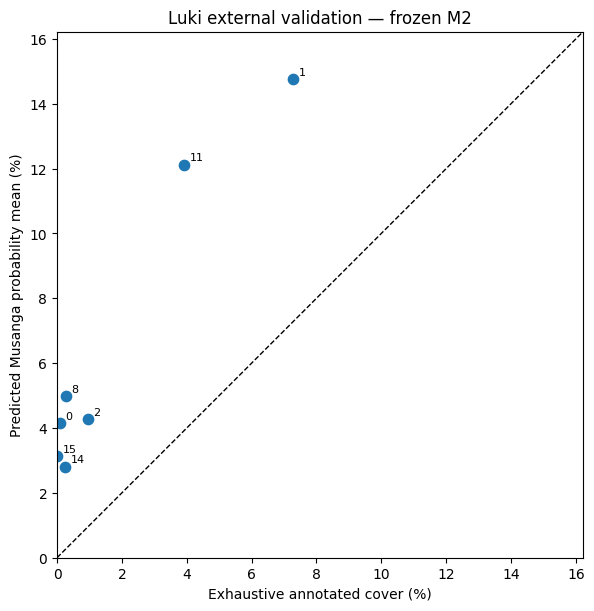

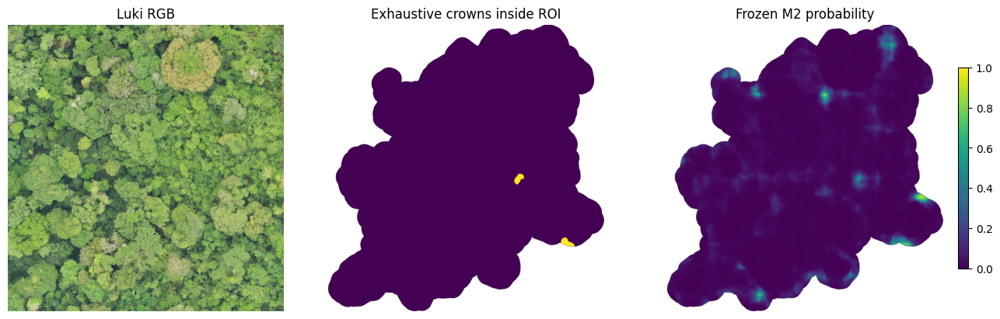

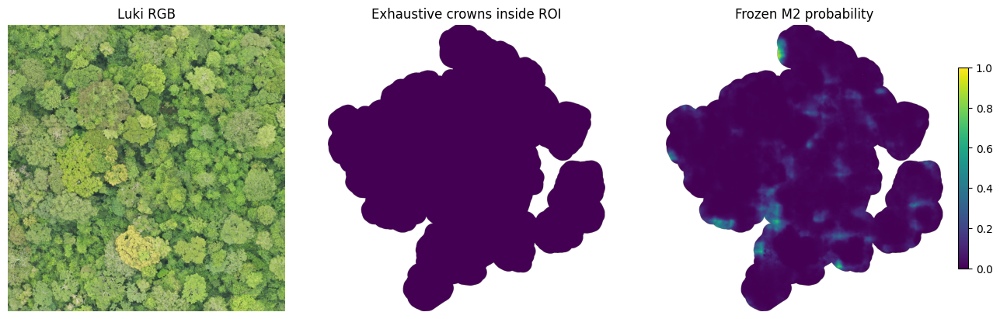

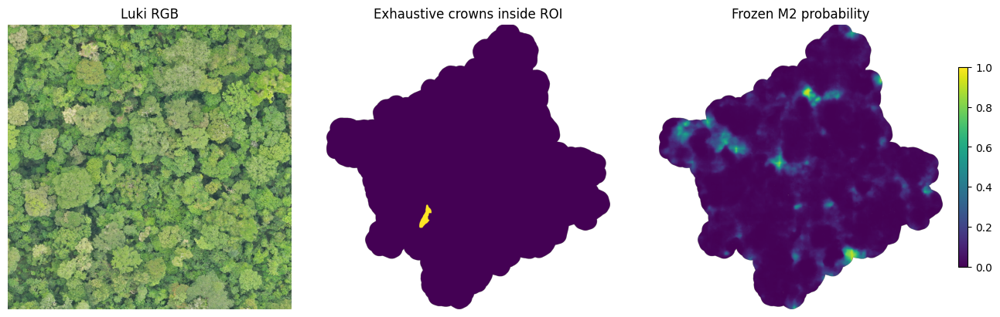

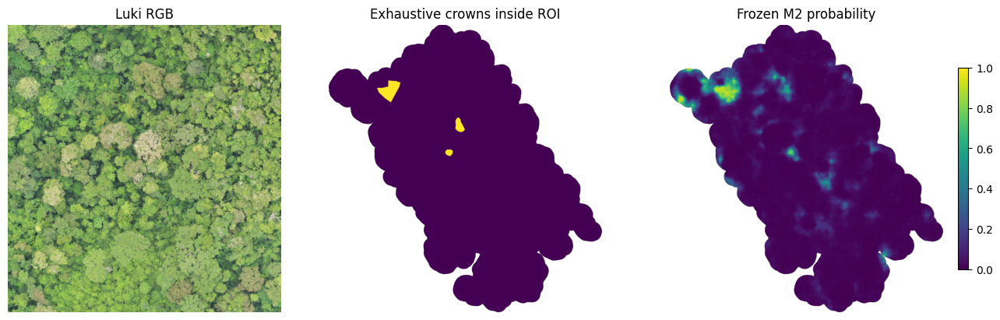

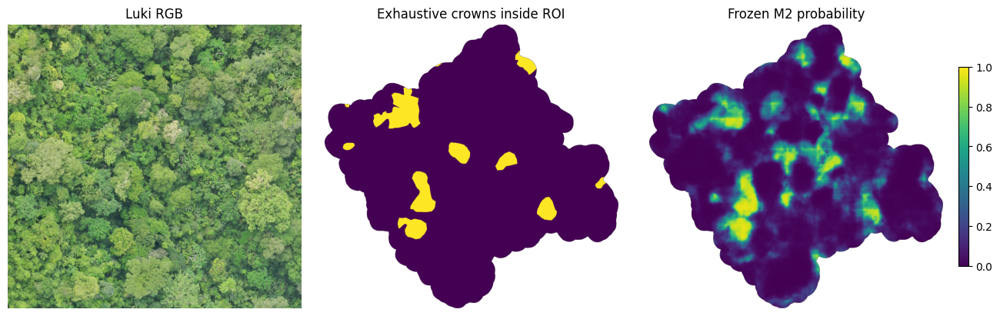

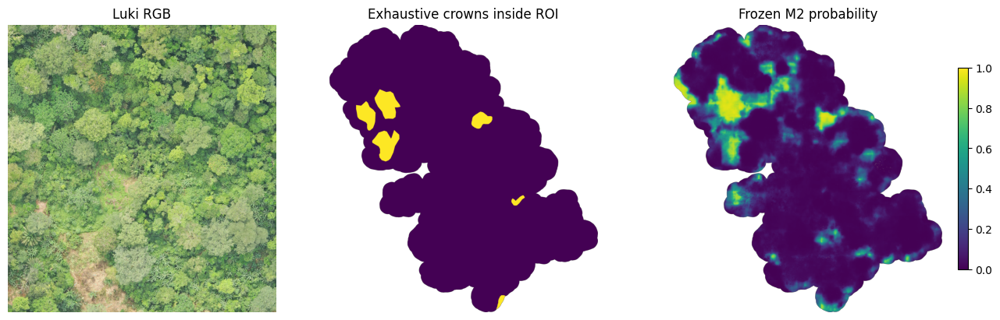

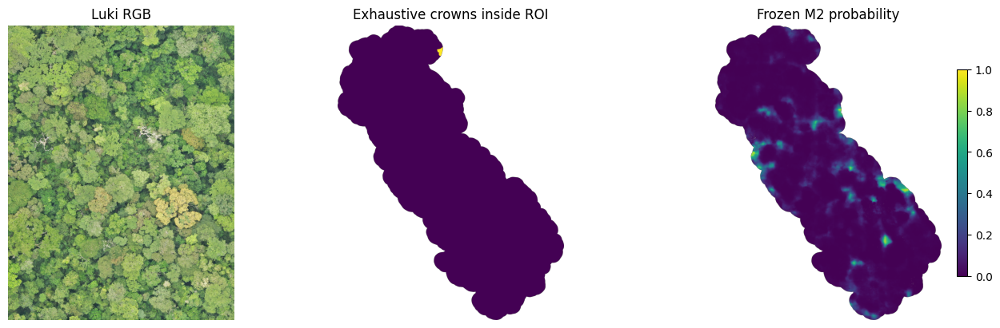

In [8]:
fig,ax=plt.subplots(figsize=(6,6),layout='constrained')
ax.scatter(score.observed_pct,score.predicted_pct,s=55)
limit=max(10,float(np.maximum(score.observed_pct.max(),score.predicted_pct.max()))*1.1)
ax.plot([0,limit],[0,limit],'k--',lw=1)
for row in score.itertuples(index=False):
    ax.annotate(str(row.original_circle_row),(row.observed_pct,row.predicted_pct),xytext=(4,3),textcoords='offset points',fontsize=8)
ax.set(xlim=(0,limit),ylim=(0,limit),xlabel='Exhaustive annotated cover (%)',
       ylabel='Predicted Musanga probability mean (%)',
       title='Luki external validation — frozen M2')
ax.set_aspect('equal')
fig.savefig(OUT/'05_Luki_northern7_scatter.png',dpi=180);plt.show();plt.close(fig)
with rasterio.open(RGB) as src:
    for idx in range(len(cir)):
        r=registry.iloc[idx];win=Window(int(r.col),int(r.row),int(r.width),int(r.height))
        rgb=src.read([1,2,3],window=win,masked=True).filled(0).transpose(1,2,0)
        ref=burn_geoms(crown.geometry,win,src)
        roi=burn_geoms([cir.geometry.iloc[idx]],win,src)
        with rasterio.open(r.path) as f:p=f.read(1).astype('float32')
        p[p==NODATA]=np.nan;p/=SCALE
        fig,axs=plt.subplots(1,3,figsize=(13,4),layout='constrained')
        axs[0].imshow(rgb);axs[0].set_title('Luki RGB')
        axs[1].imshow(np.ma.masked_where(~roi,ref),vmin=0,vmax=1);axs[1].set_title('Exhaustive crowns inside ROI')
        im=axs[2].imshow(np.ma.masked_where(~roi,p),vmin=0,vmax=1)
        axs[2].set_title('Frozen M2 probability');fig.colorbar(im,ax=axs[2],shrink=.7)
        for ax in axs:ax.axis('off')
        fig.savefig(OUT/f'05_Luki_circle_original_{int(cir.original_circle_row.iloc[idx]):03d}_panels.png',dpi=160)
        plt.show();plt.close(fig)

## 05B — Northern-seven darkness diagnostic with NB01 training-site comparators

Re-read original Baego, MOS, Yangambi and Yoko raster windows from the audited NB01/NB03 sources. Within the seven selected Luki exhaustive circles, compare brightness, shadow-related false positives and reference-negative dark/bright strata. This is a read-only diagnostic using cached inference. Brightness alone does not prove cast shadow.


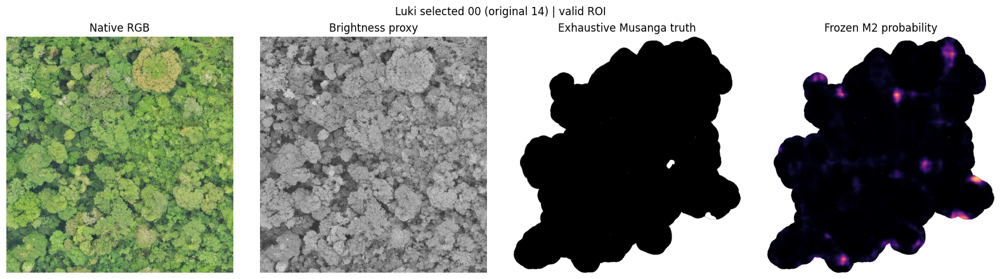

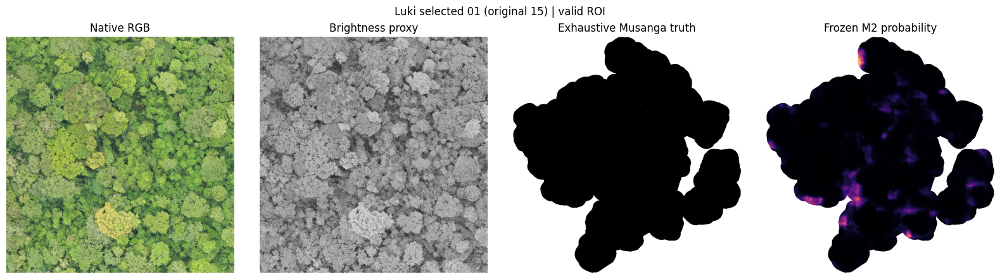

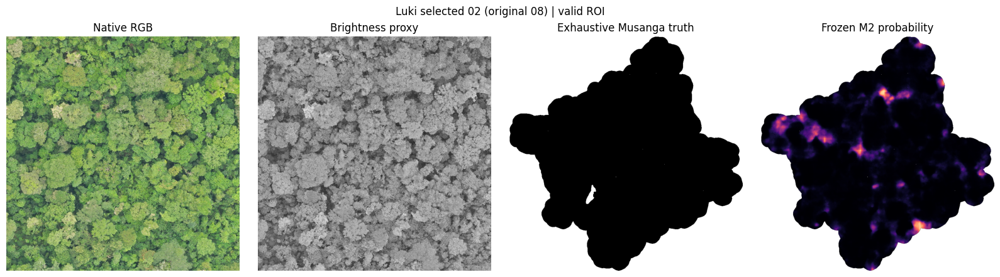

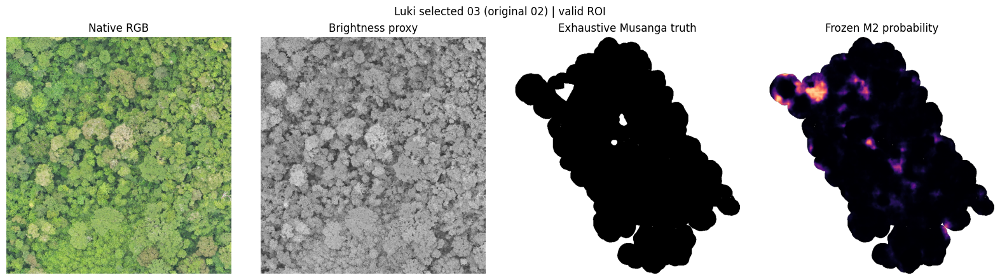

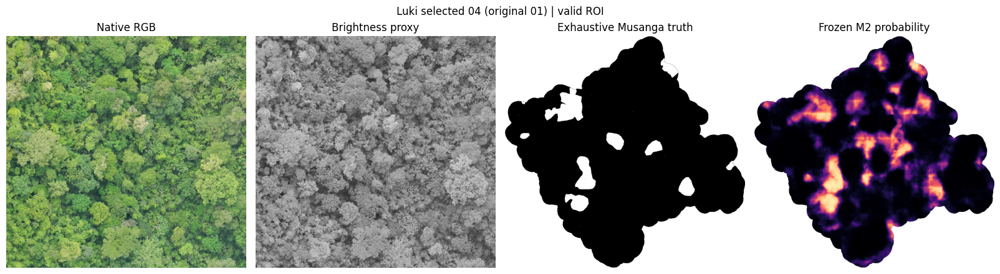

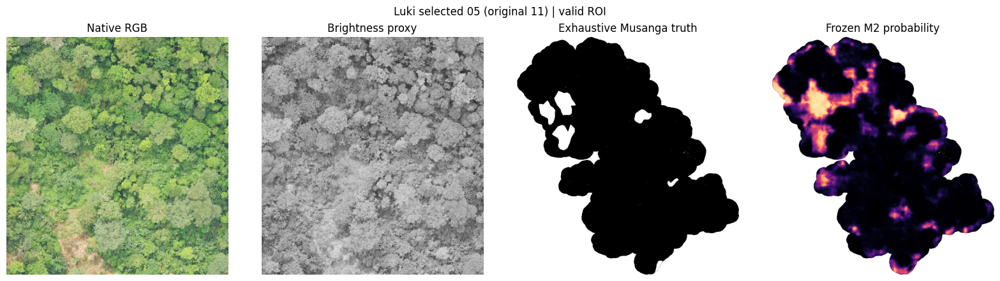

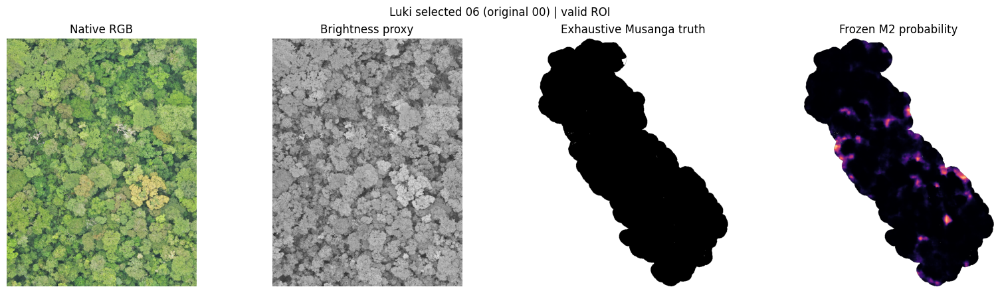

=== RGB BRIGHTNESS: original training mosaics vs Luki exhaustive circles ===


,site,n,mean,median,q10,q25,q75,dark_below_010,dark_below_020
0,Baego,72000,0.442,0.448,0.220,0.328,0.553,0.003,0.074
1,Luki,175000,0.554,0.577,0.336,0.453,0.665,0.000,0.006
2,MOS,72000,0.422,0.422,0.253,0.330,0.507,0.001,0.038
3,Yangambi,72000,0.389,0.392,0.187,0.279,0.491,0.015,0.119
4,Yoko,72000,0.417,0.428,0.239,0.333,0.505,0.002,0.056


=== FALSE POSITIVES IN REFERENCE-NEGATIVE LUKI PIXELS ===


,brightness_bin,n,mean_probability,fraction_ge_05,mean_brightness
0,"(-0.001, 0.1]",1.0,0.014,0.000,0.094
1,"(0.1, 0.2]",1106.0,0.049,0.009,0.183
2,"(0.2, 0.3]",10270.0,0.075,0.019,0.258
3,"(0.3, 0.4]",18551.0,0.093,0.034,0.353
4,"(0.4, 0.5]",27073.0,0.088,0.038,0.453
5,"(0.5, 0.6]",39218.0,0.058,0.022,0.553
6,"(0.6, 0.75]",64401.0,0.031,0.010,0.667
7,"(0.75, 1.001]",11207.0,0.023,0.006,0.793


=== NEGATIVE PIXELS: DARKEST 20% vs BRIGHTEST 20%, PER CIRCLE ===


,circle_id,dark_n,bright_n,dark_brightness,bright_brightness,dark_mean_probability,bright_mean_probability,dark_fpr,bright_fpr,delta_probability,delta_fpr
0,0,4984,4984,0.318,0.718,0.038,0.014,0.004,0.002,0.025,0.003
1,1,5000,5000,0.331,0.736,0.054,0.011,0.006,0.000,0.042,0.006
2,2,4989,4989,0.315,0.720,0.073,0.023,0.019,0.002,0.050,0.017
3,3,4958,4958,0.336,0.735,0.059,0.016,0.011,0.003,0.043,0.007
4,4,4644,4644,0.295,0.715,0.144,0.050,0.059,0.020,0.094,0.039
5,5,4796,4797,0.364,0.775,0.170,0.039,0.101,0.015,0.130,0.085
6,6,4997,4997,0.339,0.749,0.075,0.015,0.016,0.001,0.061,0.015


Equal-circle mean dark-minus-bright probability: 0.064
Equal-circle mean dark-minus-bright false-positive rate: 0.025
Circles with higher false-positive rate in darkness: 7 of 7


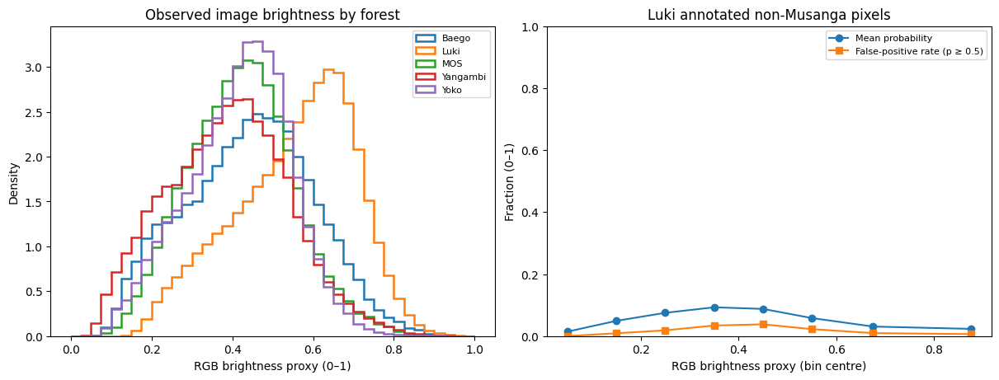

Saved diagnostics: /content/drive/MyDrive/Colab Notebooks/Musanga/Final/Outputs/V3_1/07_Luki_northern7_validation/05B_illumination_diagnostic
Interpretation: association only. Dark vegetation is not necessarily cast shadow.
Training sites use sampled exhaustive windows; Luki uses the seven northernmost circles.
NO retraining, threshold tuning, radiometric normalization or additional inference.


In [9]:
# NB07 / 05B — Illumination-domain audit; read-only, no GPU inference.
from rasterio.windows import Window
from rasterio.features import rasterize
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize

DARK_OUT=OUT/'05B_illumination_diagnostic'
DARK_OUT.mkdir(parents=True,exist_ok=True)
SEED=20261026
rng=np.random.default_rng(SEED)
BRIGHT_BINS=np.array([0,.10,.20,.30,.40,.50,.60,.75,1.001])
# Linear RGB-weighted luminance proxy (not a physical shadow classification).
def brightness(raw):
    a=raw.filled(0).astype(np.float32)/255.
    return (.2126*a[0]+.7152*a[1]+.0722*a[2]).astype('float32')

def sample_idx(mask,max_n,generator):
    idx=np.flatnonzero(mask.ravel())
    return generator.choice(idx,size=min(max_n,len(idx)),replace=False) if len(idx) else idx

def sample_rgb(raw,maximum,generator):
    valid=valid_rgb(raw)
    ids=sample_idx(valid,maximum,generator)
    return brightness(raw).ravel()[ids]

# Source comparison: use NB01 exhaustive 512-pixel candidate windows,
# paired to the original input-audit mosaic paths from NB03.
audit_path=ROOT/'Outputs/V3_1/00_input_audit/00_input_manifest.json'
ref_path=ROOT/'Outputs/V3_1/01_reference_data_no_MOS34'
assert audit_path.exists() and (ref_path/'01_candidate_windows.csv').exists()
audit05=json.loads(audit_path.read_text())
mosaics05={m['file']:Path(m['path']) for m in audit05['mosaics']}
wins05=pd.read_csv(ref_path/'01_candidate_windows.csv')
links05=pd.read_csv(ref_path/'01_circle_spatial_folds.csv')
assert {'mosaic','kind','col','row','width','height'}.issubset(wins05.columns)
assert 'site' in links05 and 'mosaic' in links05
site_by_mosaic=links05[['mosaic','site']].drop_duplicates()
assert not site_by_mosaic.mosaic.duplicated().any()
trainwins=wins05[wins05.kind=='exhaustive'].copy()
site_lookup=site_by_mosaic.set_index('mosaic')['site'].to_dict()
assert all(site_lookup.get(m)==site for m,site in zip(trainwins.mosaic,trainwins.site)), 'NB01 site-mosaic reference mismatch'
trainwins=trainwins[trainwins.site.isin(['Baego','MOS','Yangambi','Yoko'])]
assert trainwins.site.nunique()==4,('Training site windows missing',trainwins.site.unique())
train_samples=[]
for site,subset in trainwins.groupby('site',sort=True):
    subset=subset.sample(n=min(24,len(subset)),random_state=SEED)
    values=[]
    for mosaic,items in subset.groupby('mosaic'):
        assert mosaic in mosaics05 and mosaics05[mosaic].exists(),('Training mosaic absent',mosaic)
        with rasterio.open(mosaics05[mosaic]) as ds:
            for q in items.itertuples(index=False):
                win=Window(int(q.col),int(q.row),int(q.width),int(q.height))
                assert win.col_off>=0 and win.row_off>=0
                assert win.col_off+win.width<=ds.width and win.row_off+win.height<=ds.height
                raw=ds.read([1,2,3],window=win,masked=True)
                v=sample_rgb(raw,3000,rng)
                if len(v):values.append(v)
    assert values,('No valid training RGB samples',site)
    v=np.concatenate(values)
    train_samples.append(pd.DataFrame({'site':site,'brightness':v}))
train_rgb=pd.concat(train_samples,ignore_index=True)

# Luki: within EXACT exhaustive evaluation masks used in Section 04.
# Bounded random subsampling avoids loading all ~68 million evaluated pixels.
luki_rows=[]
visual_ids=list(range(7))
for rec in registry.itertuples(index=False):
    cid=int(rec.circle_id)
    win=Window(int(rec.col),int(rec.row),int(rec.width),int(rec.height))
    with rasterio.open(RGB) as src,rasterio.open(rec.path) as pred:
        raw=src.read([1,2,3],window=win,masked=True)
        valid=valid_rgb(raw)
        inside=burn_geoms([cir.geometry.iloc[cid]],win,src)&valid
        truth=burn_geoms(crown.geometry,win,src)
        packed=pred.read(1)
        mask=inside&(packed!=NODATA)
        assert np.array_equal(mask,inside),('Prediction NoData inside Luki circle',cid)
        ids=sample_idx(mask,25000,rng)
        if len(ids)==0:continue
        b=brightness(raw).ravel()[ids]
        y=truth.ravel()[ids]
        p=packed.ravel()[ids].astype('float32')/SCALE
        luki_rows.append(pd.DataFrame({'site':'Luki','circle_id':cid,'original_circle_row':int(cir.original_circle_row.iloc[cid]),
            'brightness':b,'reference_positive':y,'probability':p,
            'hard_positive':p>=.5}))
        if cid in visual_ids:
            # Full diagnostic panels on a bounded spatial crop, preserving georeferencing.
            H,W=raw.shape[1:]
            stride=max(1,int(np.ceil(max(H,W)/850)))
            rgb=np.moveaxis(raw.filled(0)[:,::stride,::stride],0,-1)
            fig,axes=plt.subplots(1,4,figsize=(16,4.3),constrained_layout=True)
            axes[0].imshow(rgb);axes[0].set_title('Native RGB')
            axes[1].imshow(brightness(raw)[::stride,::stride],vmin=0,vmax=1,cmap='gray')
            axes[1].set_title('Brightness proxy')
            axes[2].imshow(np.where(inside,truth,np.nan)[::stride,::stride],
                           vmin=0,vmax=1,cmap='gray')
            axes[2].set_title('Exhaustive Musanga truth')
            axes[3].imshow(np.where(inside,packed/SCALE,np.nan)[::stride,::stride],
                           vmin=0,vmax=1,cmap='magma')
            axes[3].set_title('Frozen M2 probability')
            for ax in axes:ax.axis('off')
            fig.suptitle(f'Luki selected {cid:02d} (original {int(cir.original_circle_row.iloc[cid]):02d}) | valid ROI')
            fig.savefig(DARK_OUT/f'circle_original_{int(cir.original_circle_row.iloc[cid]):02d}_illumination_panels.png',dpi=150)
            plt.show();plt.close(fig)

luki05=pd.concat(luki_rows,ignore_index=True)
assert luki05.circle_id.nunique()==len(cir)
all_rgb=pd.concat([train_rgb,luki05[['site','brightness']]],ignore_index=True)
rgb_stats=all_rgb.groupby('site').brightness.agg(
    n='size',mean='mean',median='median',
    q10=lambda x:x.quantile(.10),q25=lambda x:x.quantile(.25),
    q75=lambda x:x.quantile(.75),dark_below_010=lambda x:(x<.10).mean(),
    dark_below_020=lambda x:(x<.20).mean()).reset_index()
rgb_stats.to_csv(DARK_OUT/'training_sites_vs_Luki_brightness.csv',index=False)
print('=== RGB BRIGHTNESS: original training mosaics vs Luki exhaustive circles ===')
display(rgb_stats.round(3))

# Class-specific brightness response: negative pixels matter most for the hypothesis.
luki05['brightness_bin']=pd.cut(luki05.brightness,BRIGHT_BINS,include_lowest=True)
luki05['error_type']=np.select(
    [(luki05.hard_positive)&(~luki05.reference_positive),
     (~luki05.hard_positive)&(luki05.reference_positive),
     (luki05.hard_positive)&(luki05.reference_positive)],
    ['FP','FN','TP'],default='TN')
def group_response(t):
    return pd.Series({'n':len(t),
        'mean_probability':t.probability.mean(),
        'fraction_ge_05':t.hard_positive.mean(),
        'mean_brightness':t.brightness.mean()})
dark_by_class=luki05.groupby(
    ['reference_positive','brightness_bin'],observed=True
).apply(group_response,include_groups=False).reset_index()
dark_by_class.to_csv(DARK_OUT/'Luki_probability_by_brightness_and_truth.csv',index=False)
neg05=luki05[~luki05.reference_positive].copy()
fpr_by_bin=neg05.groupby('brightness_bin',observed=True).apply(
    group_response,include_groups=False).reset_index()
fpr_by_bin.to_csv(DARK_OUT/'Luki_negative_false_positives_by_brightness.csv',index=False)
print('=== FALSE POSITIVES IN REFERENCE-NEGATIVE LUKI PIXELS ===')
display(fpr_by_bin.round(3))

# Balanced within-circle contrast: do not let one circle or abundance regime
# dominate the shadow test. Low/high brightness are fixed within each circle
# using its NEGATIVE reference pixels alone.
contrasts=[]
for cid,g in neg05.groupby('circle_id'):
    lo,hi=g.brightness.quantile([.20,.80])
    dark=g[g.brightness<=lo]
    light=g[g.brightness>=hi]
    if len(dark)<20 or len(light)<20:continue
    contrasts.append(dict(circle_id=cid,dark_n=len(dark),bright_n=len(light),
        dark_brightness=dark.brightness.mean(),bright_brightness=light.brightness.mean(),
        dark_mean_probability=dark.probability.mean(),
        bright_mean_probability=light.probability.mean(),
        dark_fpr=dark.hard_positive.mean(),bright_fpr=light.hard_positive.mean(),
        delta_probability=dark.probability.mean()-light.probability.mean(),
        delta_fpr=dark.hard_positive.mean()-light.hard_positive.mean()))
contrast=pd.DataFrame(contrasts)
contrast.to_csv(DARK_OUT/'Luki_dark_vs_bright_within_circle.csv',index=False)
print('=== NEGATIVE PIXELS: DARKEST 20% vs BRIGHTEST 20%, PER CIRCLE ===')
display(contrast.round(3))
print('Equal-circle mean dark-minus-bright probability:',
      round(float(contrast.delta_probability.mean()),3))
print('Equal-circle mean dark-minus-bright false-positive rate:',
      round(float(contrast.delta_fpr.mean()),3))
print('Circles with higher false-positive rate in darkness:',
      int((contrast.delta_fpr>0).sum()),'of',len(contrast))

fig,axs=plt.subplots(1,2,figsize=(12,4.5),constrained_layout=True)
for site,grp in all_rgb.groupby('site'):
    axs[0].hist(grp.brightness,bins=np.linspace(0,1,41),
                density=True,histtype='step',linewidth=1.8,label=site)
axs[0].set(xlabel='RGB brightness proxy (0–1)',ylabel='Density',
           title='Observed image brightness by forest')
axs[0].legend(fontsize=8)
centers=np.array([interval.mid for interval in fpr_by_bin.brightness_bin])
axs[1].plot(centers,fpr_by_bin.mean_probability,'o-',label='Mean probability')
axs[1].plot(centers,fpr_by_bin.fraction_ge_05,'s-',label='False-positive rate (p ≥ 0.5)')
axs[1].set(xlabel='RGB brightness proxy (bin centre)',ylabel='Fraction (0–1)',
           ylim=(0,1),title='Luki annotated non-Musanga pixels')
axs[1].legend(fontsize=8)
fig.savefig(DARK_OUT/'brightness_domain_and_false_positives.png',dpi=180)
plt.show();plt.close(fig)
print('Saved diagnostics:',DARK_OUT)
print('Interpretation: association only. Dark vegetation is not necessarily cast shadow.')
print('Training sites use sampled exhaustive windows; Luki uses the seven northernmost circles.')
print('NO retraining, threshold tuning, radiometric normalization or additional inference.')


## 06 — Supplementary Nadine-positive crown agreement restricted to selected circles

Use newly re-read `Tree_Annotation_Luki_Nadine.shp` positives, intersect each polygon with the seven selected evaluation circles, and summarize probabilities over the intersected valid pixels. Polygon pieces can occur in more than one circle; they are reported as *circle–polygon intersections*, not independent whole crowns. This is positive-only verification, **not full-mosaic segmentation accuracy**.


In [10]:
# Supplementary Nadine comparison ONLY inside seven selected exhaustive circles.
# Reuse the existing seven circle prediction GeoTIFFs; do not load full mosaic.
nad_records=[]
with rasterio.open(RGB) as src:
    for rec in registry.itertuples(index=False):
        idx=int(rec.circle_id)
        win=Window(int(rec.col),int(rec.row),int(rec.width),int(rec.height))
        circle_geom=cir.geometry.iloc[idx]
        with rasterio.open(rec.path) as ds:
            pred=ds.read(1)
        raw=src.read([1,2,3],window=win,masked=True)
        valid=valid_rgb(raw)&(pred!=NODATA)
        for original_row,g in nad_pos.geometry.items():
            if not g.intersects(circle_geom):continue
            piece=g.intersection(circle_geom)
            if piece.is_empty:continue
            inside=burn_geoms([piece],win,src)&valid
            if not inside.any():continue
            pr=pred[inside].astype('float64')/SCALE
            nad_records.append(dict(
                circle_id=idx,original_circle_row=int(rec.original_circle_row),
                nadine_annotation_row=int(original_row),n_valid_pixels=len(pr),
                mean_probability=float(pr.mean()),fraction_ge_05=float(np.mean(pr>=.5))))
nad7=pd.DataFrame(nad_records)
assert len(nad7)>0,'No Nadine-positive polygons intersect the selected seven circles'
print('=== NADINE-POSITIVE INTERSECTIONS IN SEVEN NORTHERN CIRCLES ===')
print('Number of circle-polygon intersections:',len(nad7))
print('Distinct Nadine polygon rows:',nad7.nadine_annotation_row.nunique())
display(nad7[['n_valid_pixels','mean_probability','fraction_ge_05']].describe().round(3))
nad7.to_csv(OUT/'06_Nadine_positive_northern7_circle_intersections.csv',index=False)
print('Positive-only subset comparison saved; NOT an exhaustive independent metric.')


=== NADINE-POSITIVE INTERSECTIONS IN SEVEN NORTHERN CIRCLES ===
Number of circle-polygon intersections: 18
Distinct Nadine polygon rows: 18


,n_valid_pixels,mean_probability,fraction_ge_05
count,18.000,18.000,18.000
mean,17443.833,0.398,0.348
std,22868.583,0.282,0.399
min,587.000,0.014,0.000
25%,4336.000,0.124,0.000
50%,6518.000,0.357,0.039
75%,22918.500,0.648,0.748
max,84764.000,0.832,0.946


Positive-only subset comparison saved; NOT an exhaustive independent metric.
